# Wheat prices, climate and market sentiment: trading strategy building

**Goal.** Explain and forecast monthly wheat price changes with climate (El Niño / La Niña), market sentiment extracted from USDA reports (NLP), the US dollar and oil prices, then use the forecasts to manage a position on wheat under a risk constraint.

| Variable | Source | Native frequency |
|---|---|---|
| `wheat` — wheat price (USD/t) | IMF, series PWHEAMT | monthly |
| `sentiment` — net tone of the wheat paragraph of the WASDE reports | USDA WASDE reports (PDF), word lists | ~1 report per month |
| `roni` — Relative Oceanic Niño Index (°C), El Niño / La Niña indicator | NOAA Climate Prediction Center | monthly (3-month average) |
| `dollar` — trade-weighted US dollar index | FRED: DTWEXM (until 2019) spliced with DTWEXBGS | daily |
| `wti` — WTI crude oil price (USD/barrel) | FRED: DCOILWTICO | daily |

**Outline.** 1. Data loading · 2. Data quality · 3. Data formatting · 4. Exploratory analysis · 5. Model · 6. Portfolio

**Running the notebook.** Downloaded and processed data are cached in `data/cache/`. With the cache, the notebook only needs `numpy`, `pandas`, `matplotlib`, `torch`, `transformers`, and `scikit-learn`. Without it, the download functions also use `requests`, `lxml`, `beautifulsoup4` and `pypdf`; they are imported inside these functions only.

**Sentiment analysis.** The notebook compares the rule-based score with FinBERT in the same walk-forward portfolio pipeline. Both sentiment methods use identical timing, volatility targeting, smoothing, and transaction costs, so their $1 growth curves can be compared directly.

In [122]:
import logging
import re
import time
import requests
from bs4 import BeautifulSoup
from io import BytesIO
from io import StringIO
from pathlib import Path
from urllib.parse import urljoin
from pypdf import PdfReader
from itertools import count

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from transformers import BertTokenizer, BertForSequenceClassification
import torch

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache"        # downloaded / processed data (delete the folder to refresh)
WASDE_DIR = DATA_DIR / "wasde_txt_reports"  # WASDE PDF reports (downloaded if the folder has none)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
WASDE_DIR.mkdir(parents=True, exist_ok=True)
START = "1992-01-01"

VARS = ["wheat", "sentiment", "roni", "dollar", "wti", "finbert_sentiment"]
PRICES = ["wheat", "dollar", "wti"]          # trending series, studied through their log changes
COLORS = {"wheat": "#2a78d6", "sentiment": "#eb6834", "roni": "#1baf7a", "dollar": "#d99a00", "wti": "#d55181", "finbert_sentiment": "#ff0000"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "legend.frameon": False, "font.size": 10})

## 1. Data loading

### 1.1 Market and climate data
We define a cache function so that the notebook can be run without downloading the data again. The function checks if the cache exists, otherwise it downloads the data and saves it to the cache. Note that the cache is not updated if the source data changes, so it should be deleted manually if the source data is updated.

In [ ]:
def cached(name, download):
    """Read `name` from the cache folder, or build it with `download()` and save it first."""
    path = CACHE_DIR / name
    if not path.exists():
        download().to_csv(path, index=False)
    return pd.read_csv(path, parse_dates=["date"])


def fetch_imf_wheat():
    """Monthly wheat price from the IMF primary commodity prices database (SDMX JSON API)."""
    url = ("https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/*.PWHEAMT.USD.M"
           "?c%5BTIME_PERIOD%5D=ge:1956-12-31&attributes=all&detail=full&includeHistory=true&limit=100")
    response = requests.get(url, headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"}, timeout=60)
    response.raise_for_status()
    data = response.json()["data"]
    periods = data["structures"][0]["dimensions"]["observation"][0]["values"]
    (series,) = data["dataSets"][0]["series"].values()          # exactly one series is expected
    obs = series["observations"]
    return pd.DataFrame({"date": [pd.to_datetime(periods[int(i)]["value"].replace("-M", "-")) for i in obs],
                         "wheat": pd.to_numeric([v[0] for v in obs.values()])}).sort_values("date")


SEASON_END = {"DJF": 2, "JFM": 3, "FMA": 4, "MAM": 5, "AMJ": 6, "MJJ": 7,
              "JJA": 8, "JAS": 9, "ASO": 10, "SON": 11, "OND": 12, "NDJ": 1}

def fetch_roni():
    """RONI table of the NOAA website, one value per 3-month season, dated by the last month of the season."""
    page = requests.get("https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/", timeout=60)
    page.raise_for_status()
    # the RONI table is the one whose columns are the seasons DJF ... NDJ
    table = next(t for t in pd.read_html(StringIO(page.text))
                 if {"DJF", "NDJ"} <= {str(c).split()[0] for c in t.columns})
    long = table.melt(id_vars=table.columns[0], var_name="season", value_name="roni")
    long["year"] = pd.to_numeric(long[table.columns[0]], errors="coerce")
    long["roni"] = pd.to_numeric(long["roni"], errors="coerce")
    long = long.dropna(subset=["year", "roni"])                  # drops seasons not published yet
    month = long["season"].str[:3].map(SEASON_END)
    long["date"] = pd.to_datetime({"year": long["year"].astype(int) + (month == 1),  # NDJ ends in January
                                   "month": month, "day": 1})
    return long[["date", "roni"]].sort_values("date")


def fetch_fred(series_id, name):
    """Daily series from the public CSV export of FRED (no API key needed)."""
    response = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv",
                            params={"id": series_id, "cosd": START}, timeout=60)
    response.raise_for_status()
    df = pd.read_csv(StringIO(response.text))
    df.columns = ["date", name]
    df[name] = pd.to_numeric(df[name], errors="coerce")         # days without quote become NaN
    return df


wheat_raw = cached("imf_wheat.csv", fetch_imf_wheat)
roni_raw = cached("noaa_roni.csv", fetch_roni)
dollar_old_raw = cached("fred_dtwexm.csv", lambda: fetch_fred("DTWEXM", "dollar_old"))    # major currencies, until 2019
dollar_new_raw = cached("fred_dtwexbgs.csv", lambda: fetch_fred("DTWEXBGS", "dollar_new"))  # broad index, since 2006
wti_raw = cached("fred_wti.csv", lambda: fetch_fred("DCOILWTICO", "wti"))
for name, df in {"wheat": wheat_raw, "roni": roni_raw, "dollar_old": dollar_old_raw,
                 "dollar_new": dollar_new_raw, "wti": wti_raw}.items():
    print(f"{name:11s} {len(df):5d} rows  {df['date'].min():%Y-%m-%d} -> {df['date'].max():%Y-%m-%d}")

wheat         418 rows  1992-01-01 -> 2026-10-01
roni          921 rows  1950-02-01 -> 2026-10-01
dollar_old   7304 rows  1992-01-02 -> 2019-12-31
dollar_new   5440 rows  2006-01-02 -> 2026-11-06
wti          9095 rows  1992-01-02 -> 2026-11-11



The **WASDE** (*World Agricultural Supply and Demand Estimates*) report is published monthly by the US Department of Agriculture (USDA). It provides supply-and-demand balance sheets for major crops, together with a short commentary for each crop.

For each report:

1. **Publication date.** The date is extracted from the report header. File names use several formats (`MM-DD-YYYY`, `DD-MM-YYYY`, and `MMYY`), so the file name is used only as a fallback.

2. **Wheat narrative.** The `WHEAT:` paragraph is extracted from the summary pages, excluding lines belonging to numeric tables.

3. **Sentiment scores.**

    3.1. **Rule-based score.** Words indicating supply problems (*drought*, *lower*, *tight*, etc.) are interpreted as bullish for prices. Words indicating abundant supply (*record*, *larger*, *favorable*, etc.) are interpreted as bearish. The score is

    $$
    \frac{\text{bullish words} - \text{bearish words}}
          {\text{bullish words} + \text{bearish words}},
    $$

    ranging from −1 (bearish for prices) to +1 (bullish for prices).

    3.2. **FinBERT score.** FinBERT is applied to relevant sentences from the wheat narrative. Its sentiment probabilities are converted into a price-oriented score by treating negative supply news as bullish for wheat prices and positive supply news as bearish.

In [161]:
BULLISH = {"drought", "dry", "deficit", "freeze", "frost", "damage", "reduced", "decline", "declining", "lower",
           "cut", "tight", "tightened", "shrinking", "drop", "dropped", "stress", "shortage", "delayed",
           "deteriorated", "poor"}                         # supply problems -> upward pressure on prices
BEARISH = {"record", "favorable", "bumper", "exceed", "exceeded", "abundant", "expanded", "expansion", "increase",
           "increased", "increasing", "higher", "rebound", "rebounded", "surge", "surplus", "large", "larger",
           "adequate", "improved", "improving", "heavy"}  # abundant supply -> downward pressure on prices
ERRATA = re.compile(r"revision|announcement|ending_stocks|readme", re.I)
WASDE_URL = "https://esmis.nal.usda.gov/publication/world-agricultural-supply-and-demand-estimates"

def download_wasde_reports(min_year=1992):
    """Scrape the USDA table from newest to oldest, stopping once releases prior to `min_year` are reached."""
    session = requests.Session()
    session.headers["User-Agent"] = (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36 (Research Project; contact@ensae.fr)"
    )

    for page in count():
        rows = []
        for attempt in range(3):
            try:
                listing = requests.get(WASDE_URL, params={"date": "All", "page": page}, headers=session.headers, timeout=(10, 25))
                if listing.status_code != 200:
                    time.sleep(2.0)
                    continue
                soup = BeautifulSoup(listing.content, "html.parser")
                rows = soup.select("table.cols-3 tbody tr")
                if rows:
                    break
                time.sleep(1.5)
            except requests.RequestException:
                time.sleep(2.0)

        if not rows:
            break

        soup = BeautifulSoup(listing.content, "html.parser")
        rows = soup.select("table.cols-3 tbody tr")
        if not rows:
            print(f"Page {page}: plus aucune ligne trouvée.")
            break

        reached_cutoff = False
        first_date_str = "?"

        for row in rows:
            time_tag = row.select_one("td.views-field-release-date time")
            if not time_tag or not time_tag.has_attr("datetime"):
                continue

            release_date = pd.to_datetime(time_tag["datetime"], errors="coerce")
            if pd.isna(release_date):
                continue

            if first_date_str == "?":
                first_date_str = f"{release_date:%Y-%m-%d}"

            if release_date.year < min_year:
                reached_cutoff = True
                break

            # Déjà téléchargé localement
            if any((WASDE_DIR / f"wasde-{release_date:%Y-%m-%d}{e}").exists() for e in (".pdf", ".txt")):
                continue

            # Ignorer les erratas avant même d'ouvrir la page de détail
            row_text = row.get_text(" ", strip=True)
            if ERRATA.search(row_text):
                continue

            # 1. Liens directs dans la colonne Download
            links = row.select("td.views-field-release-files a[href]")
            valid_links = []
            for a in links:
                href = a["href"].split("?", 1)[0]
                ext = Path(href).suffix.lower()
                if ext in {".pdf", ".txt"} and not ERRATA.search(Path(href).name):
                    valid_links.append((ext, urljoin(WASDE_URL, a["href"])))

            # 2. Repli sur la page "View" uniquement si nécessaire
            if not valid_links:
                view_link = row.select_one("td.views-field-search-api-operations a[href]")
                if view_link:
                    detail_url = urljoin(WASDE_URL, view_link["href"])
                    try:
                        detail_resp = session.get(detail_url, timeout=(10, 20))
                        if detail_resp.status_code == 200:
                            detail_soup = BeautifulSoup(detail_resp.content, "html.parser")
                            for a in detail_soup.select("a[href]"):
                                href = a["href"].split("?", 1)[0]
                                name = Path(href).name
                                ext = Path(href).suffix.lower()
                                if (ext in {".pdf", ".txt"} or name.casefold() == "latest") and not ERRATA.search(name):
                                    valid_links.append((ext or ".pdf", urljoin(WASDE_URL, a["href"])))
                    except requests.RequestException:
                        pass
                    time.sleep(0.25)

            if not valid_links:
                continue

            if 1995 <= release_date.year <= 1997:
                valid_links.sort(key=lambda item: 0 if item[0] == ".txt" else 1)
            else:
                valid_links.sort(key=lambda item: 0 if item[0] == ".pdf" else 1)

            ext, file_url = valid_links[0]
            local_path = WASDE_DIR / f"wasde-{release_date:%Y-%m-%d}{ext}"

            try:
                resp = session.get(file_url, timeout=(10, 30))
                if resp.status_code == 200 and (ext == ".txt" or resp.content.startswith(b"%PDF")):
                    local_path.write_bytes(resp.content)
            except requests.RequestException as exc:
                print(f"  Échec téléchargement {release_date:%Y-%m-%d} ({exc})")

            time.sleep(0.3)

        print(f"Page {page:2d} traitée (à partir de {first_date_str})")

        if reached_cutoff:
            print(f"Arrêt : année {min_year} atteinte.")
            break


def wheat_narrative(text):
    """'WHEAT:' paragraph of a report, without the lines of numeric tables."""
    start = re.search(r"W\s*H\s*E\s*A\s*T\s*:\s*", text, re.I) or re.search(r"\n\s*WHEAT\b[^\n]*\n", text, re.I)
    if not start:
        return ""
    rest = text[start.end():]
    end = re.search(r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
                    rest, re.I)
    lines = (rest[:end.start()] if end else rest[:5000]).split("\n")
    return " ".join(l.strip() for l in lines if len(re.findall(r"\b\d+(?:\.\d+)?\b", l)) < 4)


def parse_wasde(path):
    """Publication date (from standardized filename) and net wheat sentiment of one WASDE report."""
    logging.getLogger("pypdf").setLevel(logging.ERROR)
    try:
        if path.suffix.lower() == ".txt":
            pages = [path.read_text(encoding="utf-8", errors="replace")]
        else:
            pages = [page.extract_text() or "" for page in PdfReader(path).pages[:4]]
    except Exception:
        pages = [""]

    # Extract standardized ISO date YYYY-MM-DD (with fallback to legacy MM-DD-YYYY if old files remain)
    iso_match = re.search(r"((?:19|20)\d\d)-(0[1-9]|1[0-2])-([0-3]\d)", path.name)
    if iso_match:
        date = pd.to_datetime(iso_match.group(0), format="%Y-%m-%d", errors="coerce")
    else:
        legacy_match = re.search(r"(0[1-9]|1[0-2])-([0-3]\d)-((?:19|20)\d\d)", path.name)
        date = pd.to_datetime(f"{legacy_match[3]}-{legacy_match[1]}-{legacy_match[2]}", errors="coerce") if legacy_match else pd.NaT

    narrative = wheat_narrative("\n".join(pages))
    words = re.findall(r"\b[a-z]+\b", narrative.lower())

    if narrative.strip():
        if not hasattr(parse_wasde, "_finbert"):
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            tokenizer = BertTokenizer.from_pretrained("ProsusAI/finbert")
            model = BertForSequenceClassification.from_pretrained("ProsusAI/finbert").to(device)
            model.eval()
            labels = {label.lower(): i for i, label in model.config.id2label.items()}
            relevant_terms = re.compile(
                r"\b(supply|supplies|production|yield|crop|harvest|drought|weather|stocks|"
                r"ending|exports|imports|demand|consumption|use|price|prices|deficit|surplus|record)\b",
                re.I,
            )
            parse_wasde._finbert = (tokenizer, model, device, labels, relevant_terms)

        tokenizer, model, device, labels, relevant_terms = parse_wasde._finbert

        sentences = [
            s.strip()
            for s in re.split(r"(?<=[.!?])\s+", narrative.strip())
            if len(s.split()) >= 5 and relevant_terms.search(s)
        ]

        if sentences:
            inputs = tokenizer(sentences, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
            with torch.no_grad():
                probs = torch.softmax(model(**inputs).logits, dim=-1).cpu().numpy()

            p_pos = probs[:, labels["positive"]]
            p_neg = probs[:, labels["negative"]]
            p_neu = probs[:, labels["neutral"]]

            scores = np.where(p_neu > 0.80, 0.0, (p_neg - p_pos) * (1.0 - p_neu))
            finbert_sentiment = float(np.mean(scores))
        else:
            finbert_sentiment = 0.0
    else:
        finbert_sentiment = np.nan

    bull, bear = sum(w in BULLISH for w in words), sum(w in BEARISH for w in words)
    return {
        "date": date,
        "words": len(words),
        "sentiment": (bull - bear) / max(bull + bear, 1) if words else np.nan,
        "finbert_sentiment": finbert_sentiment,
        "n_bull": bull,
        "n_bear": bear,
    }


def build_wasde_table():
    download_wasde_reports()
    text_stems = {p.stem.lower() for p in WASDE_DIR.glob("*.txt")}
    files = [p for p in sorted(WASDE_DIR.iterdir())
             if p.suffix.lower() in {".pdf", ".txt"} and p.stem.lower().startswith("wasde")
             and not (p.suffix.lower() == ".pdf" and p.stem.lower() in text_stems)
             and not ERRATA.search(p.name)]
    return pd.DataFrame([{"file": p.name, **parse_wasde(p)} for p in files])


wasde_cache = CACHE_DIR / "wasde_reports.csv"

wasde = cached("wasde_reports.csv", build_wasde_table)
wasde.sort_values("date", inplace=True, na_position="last")
wasde.reset_index(drop=True, inplace=True)
print(f"{len(wasde)} WASDE reports, {wasde['sentiment'].notna().sum()} with a wheat narrative "
      f"({wasde['date'].min():%Y-%m} -> {wasde['date'].max():%Y-%m})")

Page  0 traitée (à partir de 2026-11-10)
Page  1 traitée (à partir de 2026-01-12)
Page  2 traitée (à partir de 2025-02-11)
Page  3 traitée (à partir de 2024-04-11)
Page  4 traitée (à partir de 2023-06-09)
Page  5 traitée (à partir de 2022-08-12)
Page  6 traitée (à partir de 2021-10-12)
Page  7 traitée (à partir de 2020-12-10)
Page  8 traitée (à partir de 2020-02-11)
Page  9 traitée (à partir de 2019-06-11)
Page 10 traitée (à partir de 2018-08-10)
Page 11 traitée (à partir de 2017-10-12)
Page 12 traitée (à partir de 2016-12-09)
Page 13 traitée (à partir de 2016-02-09)
Page 14 traitée (à partir de 2015-04-09)
Page 15 traitée (à partir de 2014-06-11)
Page 16 traitée (à partir de 2013-08-12)
Page 17 traitée (à partir de 2012-10-11)
Page 18 traitée (à partir de 2011-12-09)
Page 19 traitée (à partir de 2011-02-09)
Page 20 traitée (à partir de 2010-05-11)
Page 21 traitée (à partir de 2009-08-12)
Page 22 traitée (à partir de 2008-11-10)
Page 23 traitée (à partir de 2008-05-05)
Page 24 traitée 

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

434 WASDE reports, 381 with a wheat narrative (1992-01 -> 2026-11)


### Sentiment comparison

We compared the rule-based sentiment score with the FinBERT score for the same WASDE wheat narratives. The two measures generally produce similar results and move in the same direction (Pearson correlation: 0.64), indicating broad agreement in the sentiment classification. However, they are not identical: FinBERT captures sentence context and language nuance, while the rule-based method relies on predefined bullish and bearish word counts.

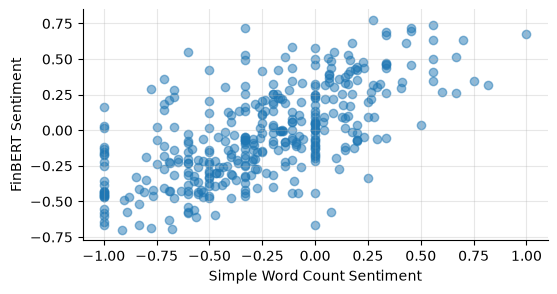

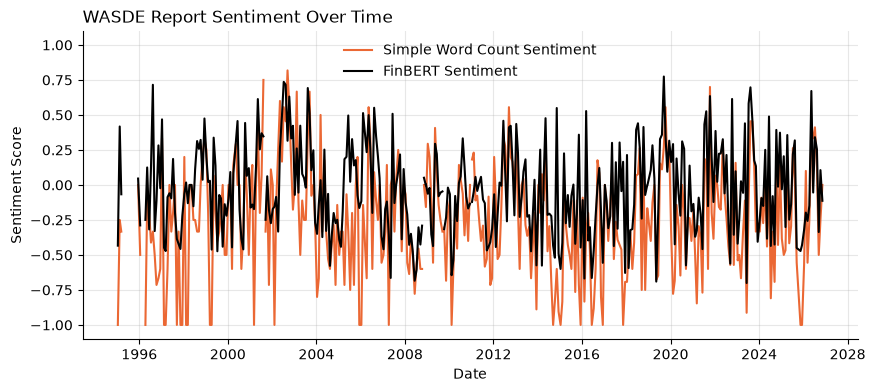

Sentiment agreement (Pearson correlation): 0.6536946394303287


In [144]:
# Compare the two sentiment scores (FinBERT vs. simple word count) on the reports that have both valid scores. The two scores are correlated but not identical, and the FinBERT score is more nuanced and less sensitive to the length of the report.
plt.figure(figsize=(6, 3))
plt.scatter(wasde["sentiment"], wasde["finbert_sentiment"], alpha=0.5)
plt.xlabel("Simple Word Count Sentiment")
plt.ylabel("FinBERT Sentiment")
plt.show()

# Display both sentiment scores over time, showing that they generally move together but can diverge in certain reports, reflecting the different methods of sentiment analysis.
plt.figure(figsize=(10, 4))
plt.plot(wasde["date"], wasde["sentiment"], label="Simple Word Count Sentiment", color=COLORS["sentiment"])
plt.plot(wasde["date"], wasde["finbert_sentiment"], label="FinBERT Sentiment", color="#000000")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.title("WASDE Report Sentiment Over Time")
plt.legend()
plt.show()

print("Sentiment agreement (Pearson correlation):", wasde[["sentiment", "finbert_sentiment"]].corr().iloc[0, 1])

## 2. Data quality
For each raw series: coverage, real frequency (median gap between observations), missing values, duplicated dates, months without data and orders of magnitude.

In [145]:
RAW = {"wheat": wheat_raw, "sentiment": wasde[["date", "sentiment"]], "finbert_sentiment": wasde[["date", "finbert_sentiment"]], "roni": roni_raw,
       "dollar_old": dollar_old_raw, "dollar_new": dollar_new_raw, "wti": wti_raw}

def quality(frame, col):
    s = frame.dropna(subset=["date"]).set_index("date")[col].sort_index()
    valid = s.dropna()
    months = valid.index.to_period("M")
    gap = valid.index.to_series().diff().dt.days.median()
    return {"start": valid.index.min().date(), "end": valid.index.max().date(), "observations": len(valid),
            "missing values": int(s.isna().sum()), "duplicated dates": int(s.index.duplicated().sum()),
            "frequency": "daily" if gap <= 4 else "monthly" if gap <= 35 else "irregular",
            "max obs. per month": int(valid.groupby(months).size().max()),
            "months without data": len(pd.period_range(months.min(), months.max(), freq="M").difference(months)),
            "min": round(valid.min(), 2), "median": round(valid.median(), 2), "max": round(valid.max(), 2)}

display(pd.DataFrame({name: quality(frame, name) for name, frame in RAW.items()}).T)

,start,end,observations,missing values,duplicated dates,frequency,max obs. per month,months without data,min,median,max
wheat,1992-01-01,2026-10-01,418,0,0,monthly,1,0,88.55,170.72,444.16
sentiment,1995-01-12,2026-11-10,381,53,0,monthly,2,4,-1.0,-0.25,1.0
finbert_sentiment,1995-01-12,2026-11-10,381,53,0,monthly,2,4,-0.7,-0.06,0.77
roni,1950-02-01,2026-10-01,921,0,0,monthly,1,0,-1.9,0.0,2.4
dollar_old,1992-01-02,2019-12-31,7094,210,0,daily,23,0,68.01,87.55,113.1
dollar_new,2006-01-02,2026-11-06,5227,213,0,daily,23,0,85.47,110.3,130.04
wti,1992-01-02,2026-11-11,8074,1021,0,daily,23,0,-36.98,56.48,145.31


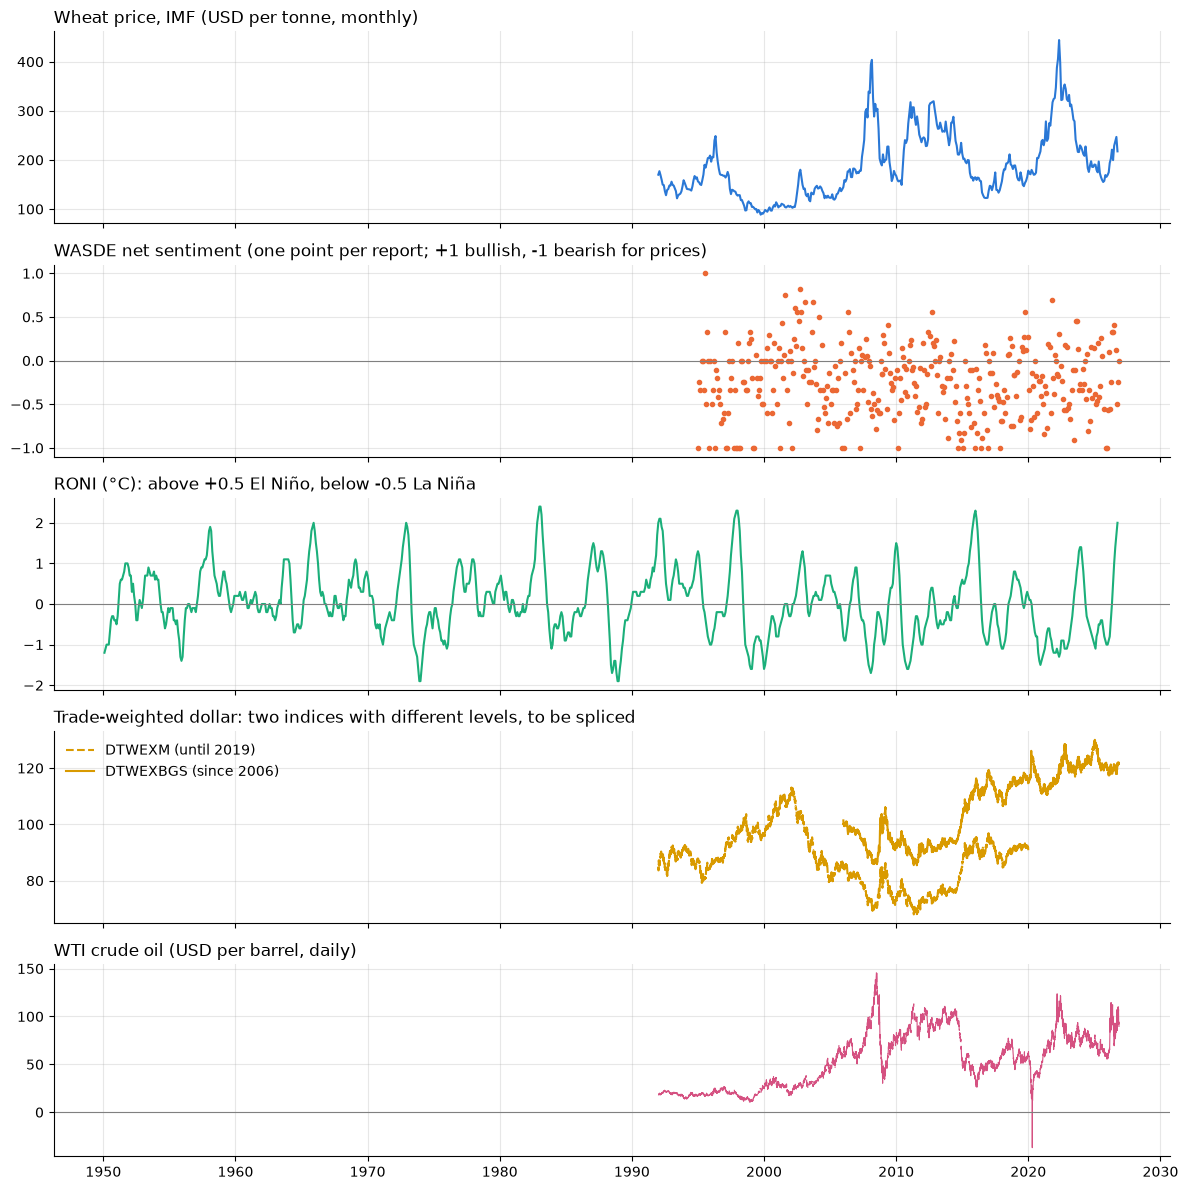

In [146]:
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
axes[0].plot(wheat_raw["date"], wheat_raw["wheat"], color=COLORS["wheat"])
axes[0].set_title("Wheat price, IMF (USD per tonne, monthly)")
axes[1].plot(wasde["date"], wasde["sentiment"], ".", color=COLORS["sentiment"])
axes[1].set_title("WASDE net sentiment (one point per report; +1 bullish, -1 bearish for prices)")
axes[2].plot(roni_raw["date"], roni_raw["roni"], color=COLORS["roni"])
axes[2].set_title("RONI (°C): above +0.5 El Niño, below -0.5 La Niña")
axes[3].plot(dollar_old_raw["date"], dollar_old_raw["dollar_old"], "--", color=COLORS["dollar"], label="DTWEXM (until 2019)")
axes[3].plot(dollar_new_raw["date"], dollar_new_raw["dollar_new"], color=COLORS["dollar"], label="DTWEXBGS (since 2006)")
axes[3].set_title("Trade-weighted dollar: two indices with different levels, to be spliced")
axes[3].legend(loc="upper left")
axes[4].plot(wti_raw["date"], wti_raw["wti"], color=COLORS["wti"], lw=0.8)
axes[4].set_title("WTI crude oil (USD per barrel, daily)")
for ax in axes[[1, 2, 4]]:
    ax.axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

In [147]:
dated = wasde.dropna(subset=["date"])
print("WTI prices <= 0:\n", wti_raw.loc[wti_raw["wti"] <= 0].to_string(index=False))
print("WASDE reports without a date:", int(wasde["date"].isna().sum()))
print("WASDE reports without a wheat narrative, by year:",
      dated.loc[dated["sentiment"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())
print("WASDE reports with a neutral score (0):", int((dated["sentiment"] == 0).sum()))
print("Day of month of the WASDE publications (expected around the 8th-12th):",
      dated["date"].dt.day.value_counts().sort_index().to_dict())

WTI prices <= 0:
       date    wti
2020-04-20 -36.98
WASDE reports without a date: 0
WASDE reports without a wheat narrative, by year: {1992: 12, 1993: 12, 1994: 12, 1995: 10, 1996: 3, 2001: 1, 2008: 1, 2009: 1, 2010: 1}
WASDE reports with a neutral score (0): 37
Day of month of the WASDE publications (expected around the 8th-12th): {1: 1, 8: 29, 9: 69, 10: 104, 11: 80, 12: 140, 13: 2, 14: 6, 15: 1, 16: 1, 28: 1}


**Findings.**
- **Wheat and RONI**: no missing month.
- **FRED daily series**: missing days (holidays, and some gaps in the WTI series around 1999-2004). They do not matter once the data are averaged by month. The only negative WTI price (April 2020) is a real market event.
- **WASDE**:
  - the 1992-1994 PDFs are scanned images without text;
  - a few months have no full report.

  These months are kept as missing values, not as a neutral score.
- **Dating check**: the publication days cluster around the 8th-12th, the usual WASDE calendar.

## 3. Data formatting
- **Monthly frequency**: monthly mean of the observations of each month; for daily series, the last month is dropped while it is still in progress.
- **Dollar**: the old index (until 2019) is chained onto the new one (since 2006) at their first common month. Their ratio is not constant, so a single scaling factor would create an artificial jump.
- **Common sample**: months where the 5 variables are observed. The variables are then standardised (mean 0, standard deviation 1) to be compared on the same scale.

In [148]:
def to_monthly(frame, col, daily=False):
    """Monthly mean; for a daily series the last month is dropped if it is still in progress."""
    s = frame[["date", col]].dropna().set_index("date")[col].sort_index()
    grouped = s.groupby(s.index.to_period("M").to_timestamp())
    monthly, counts = grouped.mean(), grouped.size()
    if daily and counts.iloc[-1] < 0.7 * counts.median():
        monthly = monthly.iloc[:-1]
    return monthly

dollar_old = to_monthly(dollar_old_raw, "dollar_old", daily=True)
dollar_new = to_monthly(dollar_new_raw, "dollar_new", daily=True)
junction = dollar_new.index[0]                                  # first common month
dollar = dollar_new.combine_first(dollar_old * dollar_new[junction] / dollar_old[junction])

monthly = pd.concat({"wheat": to_monthly(wheat_raw, "wheat"),
                     "sentiment": to_monthly(wasde, "sentiment"),
                     "finbert_sentiment": to_monthly(wasde, "finbert_sentiment"),
                     "roni": to_monthly(roni_raw, "roni"), "dollar": dollar,
                     "wti": to_monthly(wti_raw, "wti", daily=True)}, axis=1, sort=True).loc[START:].asfreq("MS")

display(pd.DataFrame({"first month": monthly.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
                      "last month": monthly.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
                      "months": monthly.notna().sum(),
                      "gaps inside": monthly.apply(lambda s: s[s.first_valid_index():s.last_valid_index()].isna().sum())}))

,first month,last month,months,gaps inside
wheat,1992-01,2026-10,418,0
sentiment,1995-01,2026-11,379,4
finbert_sentiment,1995-01,2026-11,379,4
roni,1992-01,2026-10,418,0
dollar,1992-01,2026-10,418,0
wti,1992-01,2026-10,418,0


Common sample: 378 months (1995-01 -> 2026-10); months missing inside: ['2006-03', '2013-10', '2019-01', '2025-10']


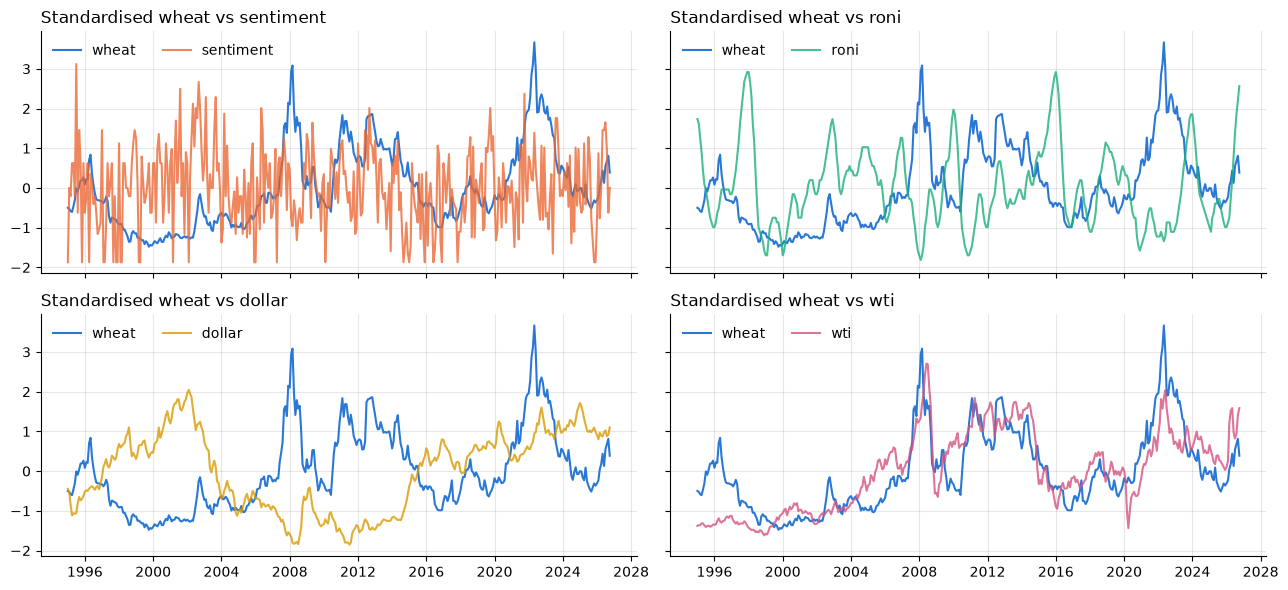

In [149]:
panel = monthly.dropna()                                        # common sample
z = (panel - panel.mean()) / panel.std()                        # standardised variables
holes = pd.date_range(panel.index[0], panel.index[-1], freq="MS").difference(panel.index)
print(f"Common sample: {len(panel)} months ({panel.index[0]:%Y-%m} -> {panel.index[-1]:%Y-%m}); "
      f"months missing inside: {[f'{d:%Y-%m}' for d in holes]}")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, VARS[1:]):
    ax.plot(z["wheat"], color=COLORS["wheat"], label="wheat")
    ax.plot(z[c], color=COLORS[c], label=c, alpha=0.8)
    ax.set_title(f"Standardised wheat vs {c}")
    ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

In [150]:
# Extreme monthly moves (log changes for prices, differences for sentiment and RONI), robust z-score
moves = pd.DataFrame({c: np.log(monthly[c]).diff() if c in PRICES else monthly[c].diff() for c in VARS})
robust_z = 0.6745 * (moves - moves.median()) / (moves - moves.median()).abs().median()
extremes = robust_z.stack()
display(extremes[extremes.abs() > 4].sort_values(key=abs, ascending=False).head(10).round(2).rename("robust z-score").to_frame())

,,robust z-score
date,,
2020-04-01,wti,-7.51
2020-03-01,wti,-7.25
2020-05-01,wti,6.89
2008-10-01,dollar,5.08
1998-06-01,roni,-4.72
2008-12-01,wti,-4.46
2008-10-01,wheat,-4.39
2026-03-01,wti,4.33
2012-07-01,wheat,4.28


The largest moves are real market events (2008 financial crisis, oil collapse of 2020, wheat drought rally of 2012) and are kept. The RONI moves look extreme only because the index changes slowly in steps of 0.1 °C.

## 4. Exploratory analysis: correlations
Prices trend over time, so two price series can look correlated without any real link (spurious correlation). Correlations are therefore also computed on **monthly changes**: log changes for the prices; sentiment and RONI stay in levels as they fluctuate around a mean.

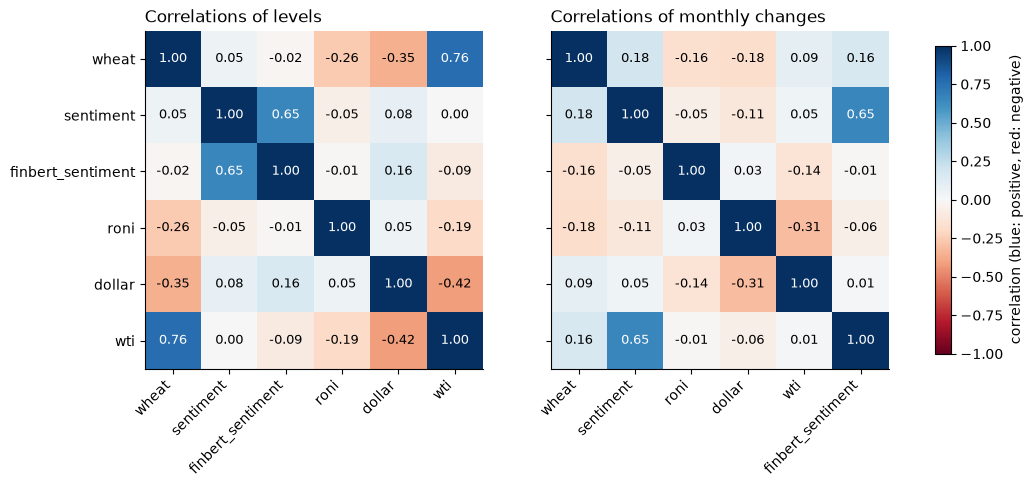

In [151]:
changes = pd.DataFrame({c: np.log(monthly[c]).diff() if c in PRICES else monthly[c] for c in VARS})

def heatmap(ax, corr, title, row_labels=True):
    image = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.index if row_labels else [])
    for i in range(len(corr)):
        for j in range(len(corr)):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(value) > 0.6 else "black")     # readable on dark cells
    ax.set_title(title)
    ax.grid(False)
    return image

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
heatmap(axes[0], panel.corr(), "Correlations of levels")
image = heatmap(axes[1], changes.dropna().corr(), "Correlations of monthly changes", row_labels=False)
fig.colorbar(image, ax=axes, shrink=0.8, label="correlation (blue: positive, red: negative)")
plt.show()

**Lagged correlations.** Correlation between the wheat change of month *t* and each variable in month *t − k*. For *k* > 0 the variable leads wheat, which is what a forecast needs. Coloured bars exceed the 5 % significance threshold (grey band).

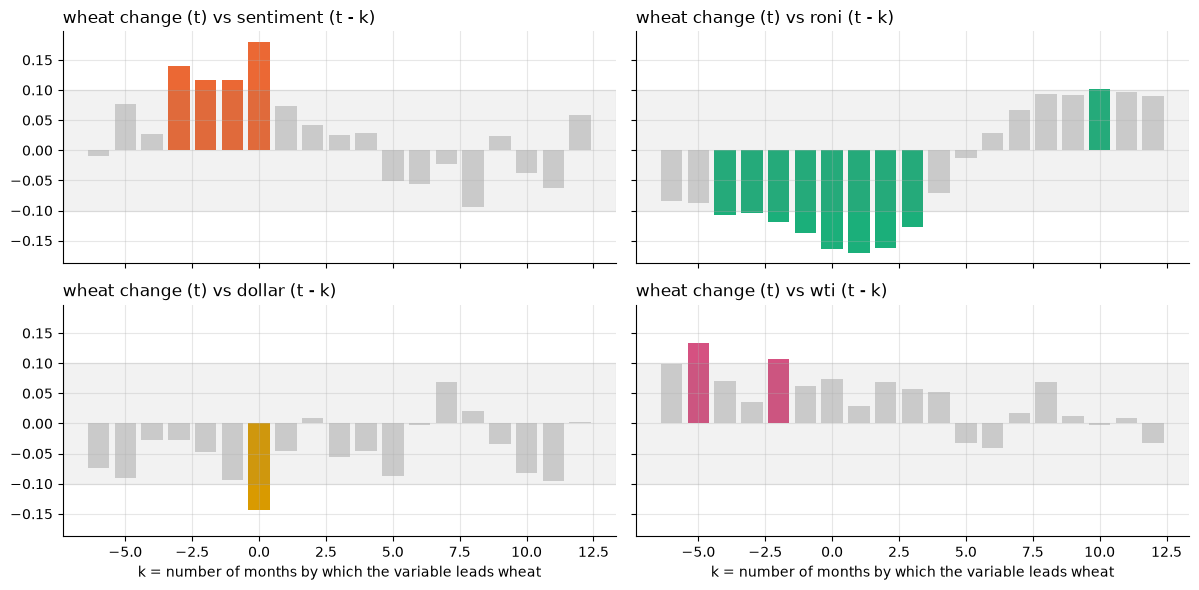

,mean,std,count
roni,,,
La Niña,0.0126,0.0689,157
neutral,-0.0018,0.0737,173
El Niño,-0.0169,0.0495,86


In [152]:
LAGS = range(-6, 13)
band = 1.96 / np.sqrt(len(changes.dropna()))
lag_corr = pd.DataFrame({c: [changes["wheat"].corr(changes[c].shift(k)) for k in LAGS] for c in VARS[1:]}, index=LAGS)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, lag_corr):
    ax.bar(lag_corr.index, lag_corr[c], color=[COLORS[c] if abs(v) > band else "lightgray" for v in lag_corr[c]])
    ax.axhspan(-band, band, color="gray", alpha=0.1)
    ax.set_title(f"wheat change (t) vs {c} (t - k)")
for ax in axes[1]:
    ax.set_xlabel("k = number of months by which the variable leads wheat")
plt.tight_layout()
plt.show()

# Non-linear climate effect: wheat change by ENSO regime, RONI known two months before
regime = pd.cut(monthly["roni"].shift(2), [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "neutral", "El Niño"])
display(changes["wheat"].groupby(regime, observed=True).agg(["mean", "std", "count"]).round(4))

**Stability over time.** A correlation measured over 30 years can hide regime changes; the 60-month rolling correlation shows how each link evolves.

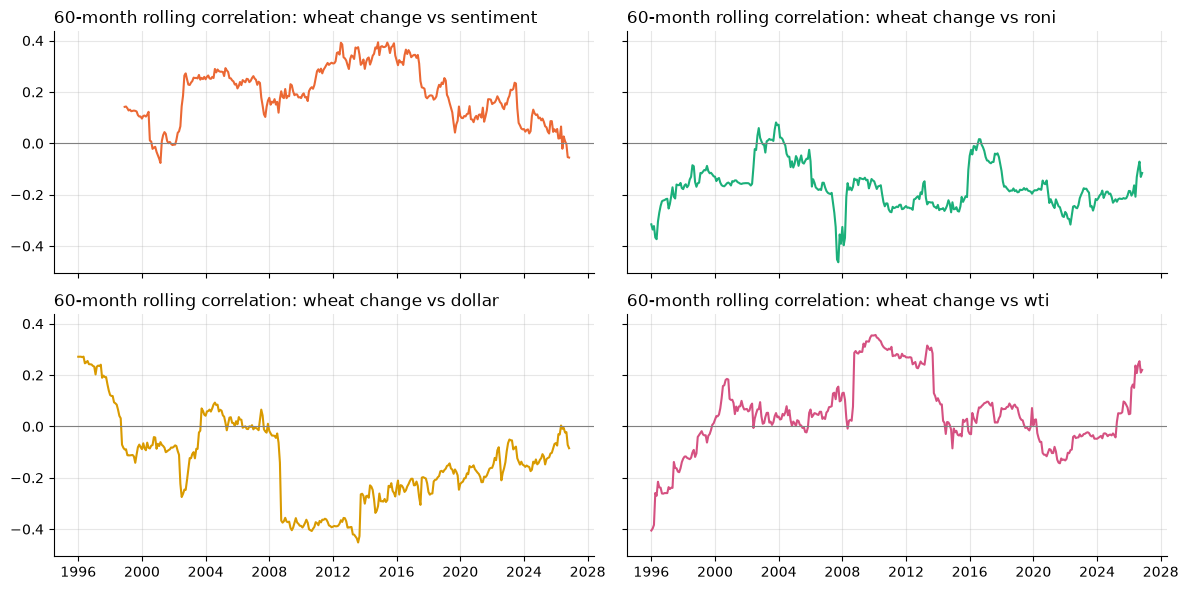

In [153]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, VARS[1:]):
    ax.plot(changes["wheat"].rolling(60, min_periods=48).corr(changes[c]), color=COLORS[c])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"60-month rolling correlation: wheat change vs {c}")
plt.tight_layout()
plt.show()

## 5. Model
The model forecasts the **wheat log return of the next month** using only information available at the time of the decision:

$$\Delta\log P_{t+1} = a + b_1\,\Delta\log \text{WTI}_{t-1} + b_2\,\Delta\log \text{Dollar}_{t-1} + b_3\,\text{Sentiment}_{t-1} + b_4\,\text{ElNiño}_{t-2} + b_5\,\text{LaNiña}_{t-2} + b_6\,\Delta\text{RONI}_{t-2} + \varepsilon$$

- **Climate.** The RONI enters through three variables built on the NOAA definition of ENSO episodes (±0.5 °C):
  - **El Niño** = max(RONI − 0.5, 0), the intensity of a warm episode;
  - **La Niña** = max(−0.5 − RONI, 0), the intensity of a cold episode;
  - **ΔRONI**, the monthly change of the RONI.

  A neutral RONI therefore has no effect, and warm and cold episodes can act differently.
- **Lags.** Each variable is taken at its last value known at the decision: month *t − 1* for oil, dollar and sentiment, month *t − 2* for the RONI, which is published one month later. A month without a WASDE report keeps the last published score.
- **Estimators.** Ordinary least squares (**OLS**), **Ridge** (penalty on squared coefficients, shrinks them all) and **Lasso** (penalty on absolute coefficients, can set some to zero). For Ridge and Lasso, the variables are standardised and the penalty is chosen by time-series cross-validation inside the training data.
- **Out-of-sample test.** Training on the first 70 % of the months, test on the last 30 %. One month is dropped between the two: its target is only known after the first test decision. The benchmark is the same OLS model with the RONI as a single linear term.

In [154]:
def make_model_data(monthly):
    """Row t: target y = wheat log return from t to t+1; features are all known at the end of month t-1."""
    roni = monthly["roni"]
    features = {   # name: (series, lag in months)
        "wti_change": (np.log(monthly["wti"]).diff(), 1),
        "dollar_change": (np.log(monthly["dollar"]).diff(), 1),
        "sentiment": (monthly["sentiment"].ffill(), 1),          # last published report
        "roni": (roni, 2),
        "el_nino": ((roni - 0.5).clip(lower=0), 2),
        "la_nina": ((-0.5 - roni).clip(lower=0), 2),
        "roni_change": (roni.diff(), 2),
    }
    if "finbert_sentiment" in monthly:
        features["finbert_sentiment"] = (monthly["finbert_sentiment"].ffill(), 1)
    log_wheat = np.log(monthly["wheat"])
    data = pd.DataFrame({"y": log_wheat.shift(-1) - log_wheat, **{n: s.shift(k) for n, (s, k) in features.items()}})
    data["vol"] = log_wheat.diff().shift(1).rolling(36).std() * np.sqrt(12)   # wheat volatility known at t-1
    return data.loc[monthly["sentiment"].first_valid_index():].dropna(subset=["y"])


def ols_newey_west(X, y, lags=12):
    """OLS coefficients and Newey-West t-statistics (robust to heteroskedasticity and autocorrelation)."""
    X = np.column_stack([np.ones(len(X)), X])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    scores = X * (y - X @ beta)[:, None]
    S = scores.T @ scores
    for k in range(1, lags + 1):                                 # Bartlett-weighted autocovariances
        G = scores[k:].T @ scores[:-k]
        S += (1 - k / (lags + 1)) * (G + G.T)
    bread = np.linalg.inv(X.T @ X)
    return beta, beta / np.sqrt(np.diag(bread @ S @ bread))


CLIMATE = ["wti_change", "dollar_change", "sentiment", "el_nino", "la_nina", "roni_change"]
COMBINED = CLIMATE + ["finbert_sentiment"]
BENCHMARK = ["wti_change", "dollar_change", "sentiment", "roni"]
ESTIMATORS = {
    "OLS": LinearRegression,
    "Ridge": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5))),
    "Lasso": lambda: make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(5))),
}
model_data = make_model_data(monthly)

sample = model_data.dropna()
n_train = int(0.7 * len(sample))
train, test = sample.iloc[:n_train - 1], sample.iloc[n_train:]
print(f"Train: {train.index[0]:%Y-%m} -> {train.index[-1]:%Y-%m} ({len(train)} months) | "
      f"test: {test.index[0]:%Y-%m} -> {test.index[-1]:%Y-%m} ({len(test)} months)")

def evaluate(model, cols):
    pred = model.predict(test[cols])
    return {"R² train": model.score(train[cols], train["y"]),
            "R² test": 1 - ((test["y"] - pred) ** 2).sum() / ((test["y"] - train["y"].mean()) ** 2).sum(),
            "RMSE test": np.sqrt(((test["y"] - pred) ** 2).mean()),
            "RMSE test, zero forecast": np.sqrt((test["y"] ** 2).mean()),
            "hit rate test": (np.sign(pred) == np.sign(test["y"])).mean()}

fitted = {name: make().fit(train[CLIMATE], train["y"]) for name, make in ESTIMATORS.items()}
results = {f"{name} - climate regimes": evaluate(model, CLIMATE) for name, model in fitted.items()}
results["OLS - RONI level (benchmark)"] = evaluate(LinearRegression().fit(train[BENCHMARK], train["y"]), BENCHMARK)
display(pd.DataFrame(results).T.round(3))

coefficients = {f"OLS t-stat ({label})": pd.Series(ols_newey_west(train[cols].to_numpy(), train["y"].to_numpy())[1][1:], index=cols)
                for label, cols in {"climate regimes": CLIMATE, "RONI level": BENCHMARK}.items()}
coefficients.update({f"{name} coefficient (standardised)": pd.Series(fitted[name][-1].coef_, index=CLIMATE)
                     for name in ["Ridge", "Lasso"]})
display(pd.DataFrame(coefficients).round(4))

Train: 1995-02 -> 2017-02 (265 months) | test: 2017-04 -> 2026-09 (114 months)


,R² train,R² test,RMSE test,"RMSE test, zero forecast",hit rate test
OLS - climate regimes,0.065,0.030,0.07,0.071,0.596
Ridge - climate regimes,0.047,0.025,0.07,0.071,0.614
Lasso - climate regimes,0.049,0.021,0.07,0.071,0.579
OLS - RONI level (benchmark),0.014,0.026,0.07,0.071,0.623


,OLS t-stat (climate regimes),OLS t-stat (RONI level),Ridge coefficient (standardised),Lasso coefficient (standardised)
dollar_change,0.4557,0.2597,0.0003,0.0000
el_nino,-1.3954,NaN,-0.0027,-0.0008
la_nina,-0.2128,NaN,0.0002,0.0000
roni,NaN,-1.4178,NaN,NaN
roni_change,-2.3683,NaN,-0.0071,-0.0107
sentiment,1.1872,1.1021,0.0022,0.0000
wti_change,0.5864,0.5867,0.0010,0.0000


The R² are small, as is usual when forecasting monthly returns of a traded commodity: most of the monthly price change is unpredictable. A model can still be useful if it gets the **sign** right more often than not, which is what the portfolio exploits.

## 6. Portfolio
The simulation runs month by month. At each date *t*, each model chooses a position $w_t \in [-1, 1]$ on wheat (fraction of capital; negative = short sale), with an ex-ante annualised volatility at most equal to a **risk target σ**. Four targets are tested: 10 %, 15 %, 20 % and 25 %. They are fixed in advance, not chosen from the results.

**Timing (no look-ahead).**

| When | What happens |
|---|---|
| end of month *t − 1* | wheat, oil, dollar and sentiment are known up to *t − 1*, RONI up to *t − 2*; the position $w_t$ is computed |
| month *t* | the position is built at the average price of the month $P_t$ |
| month *t + 1* | it is closed at the average price $P_{t+1}$: return $R_{t+1} = P_{t+1}/P_t - 1$ |

The IMF prices are monthly averages: a decision taken at the end of month *t − 1* cannot be executed at the average price of month *t − 1*, which is already past.

**Position.**
1. **Forecast** $\hat y_t$ by the model of part 5, **re-estimated every month** on the rows whose target is already known (*s* ≤ *t − 2*). For Ridge and Lasso, standardisation and penalty are re-chosen each month on these rows only.
2. **Conviction** $c_t = \tanh\big((\hat y_t - m_t)/s_t\big)$, with $m_t$, $s_t$ the mean and standard deviation of the model's forecasts on its training data: an unusually high (low) forecast gives a conviction close to +1 (−1).
3. **Risk targeting** $w^*_t = \text{clip}(c_t \cdot \sigma / \hat\sigma_t, -1, 1)$, with $\hat\sigma_t$ the wheat volatility over the last 36 known months.
4. **Smoothing** $w_t = 0.5\, w_{t-1} + 0.5\, w^*_t$, to limit trading costs.

**Benchmarks.**
- **Buy & hold**: $1 of wheat kept from the first date.
- **Random walks**: 1,000 positions following a random walk $u_t = \text{clip}(u_{t-1} + \varepsilon_t, -1, 1)$, with $\varepsilon_t \sim N(0, 0.25^2)$, scaled by $\sigma/\hat\sigma_t$ like the models.

Costs are 10 basis points per unit of position traded; cash earns 0 %. Statistics are computed over the trading period (from the first position), for all strategies.

In [155]:
SIGMAS = [0.10, 0.15, 0.20, 0.25]   # annualised risk targets
MIN_TRAIN = 60                     # months of training before the first position
SMOOTH = 0.5                       # weight of the previous position in the smoothing
COST = 0.001                       # cost per unit of position traded (10 basis points)

def walk_forward(data, features, make_model):
    """For each month t: fit on the rows s <= t-2 (targets already known) and forecast row t."""
    out = pd.DataFrame(np.nan, index=data.index, columns=["forecast", "mean", "std"])
    for i, t in enumerate(data.index):
        past = data.iloc[:max(i - 1, 0)].dropna(subset=features + ["y"])
        if len(past) < MIN_TRAIN or data.loc[t, features].isna().any():
            continue
        model = make_model().fit(past[features], past["y"])
        in_sample = model.predict(past[features])
        out.loc[t] = model.predict(data.loc[[t], features])[0], in_sample.mean(), in_sample.std()
    return out

def position(forecasts, data, sigma):
    """Conviction in [-1, 1], scaled to the risk target, capped at +/-1, then smoothed."""
    conviction = np.tanh((forecasts["forecast"] - forecasts["mean"]) / forecasts["std"].replace(0, np.nan))
    target = (conviction * sigma / data["vol"]).clip(-1, 1).fillna(0)
    return target.ewm(alpha=1 - SMOOTH, adjust=False).mean()   # w_t = 0.5 w_{t-1} + 0.5 w*_t

forecasts = {name: walk_forward(model_data, CLIMATE, make) for name, make in ESTIMATORS.items()}   # do not depend on sigma

# FinBERT uses the identical model and portfolio rules; only the sentiment feature changes.
finbert_monthly = monthly.drop(columns=["sentiment"]).rename(columns={"finbert_sentiment": "sentiment"})
finbert_model_data = make_model_data(finbert_monthly)
finbert_forecast = walk_forward(
    finbert_model_data, CLIMATE,
    lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5))),
)

# Combined regression: both sentiment measures enter as separate lagged predictors.
combined_model_data = make_model_data(monthly)
combined_forecast = walk_forward(
    combined_model_data, COMBINED,
    lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=TimeSeriesSplit(5))),
)
first = max(
    [f["forecast"].first_valid_index() for f in forecasts.values()]
    + [finbert_forecast["forecast"].first_valid_index(), combined_forecast["forecast"].first_valid_index()]
)               # first trading month
R = np.exp(model_data["y"]) - 1                    # wheat return earned by the position decided at t

rng = np.random.default_rng(0)                      # random-walk exposures, drawn once for all targets
steps = rng.normal(0, 0.25, (len(model_data), 1000))
walks = np.zeros_like(steps)
for i in range(1, len(walks)):
    walks[i] = np.clip(walks[i - 1] + steps[i], -1, 1)
walks = pd.DataFrame(walks, index=model_data.index)
print(f"Decisions {model_data.index[0]:%Y-%m} -> {model_data.index[-1]:%Y-%m}; first position in {first:%Y-%m}")

Decisions 1995-01 -> 2026-09; first position in 2000-03


In [156]:
def pnl(w):
    """Monthly return: position x wheat return, minus costs on position changes."""
    return w.mul(R, axis=0) - COST * w.diff().abs().fillna(w.abs())

def stats(p):
    p = p.loc[first:]
    value = (1 + p).cumprod()
    return pd.Series({"annual return": value.iloc[-1] ** (12 / len(p)) - 1, "volatility": p.std() * np.sqrt(12),
                      "Sharpe": p.mean() / p.std() * np.sqrt(12), "max drawdown": (value / value.cummax() - 1).min()})

def wealth(p):
    """Value of $1 invested; the return of row t is earned at t+1."""
    value = (1 + p).cumprod()
    value.index = value.index + pd.offsets.MonthBegin(1)
    return pd.concat([p.iloc[:1] * 0 + 1, value])

rows, results = {}, {}
for sigma in SIGMAS:
    positions = pd.DataFrame({name: position(f, model_data, sigma) for name, f in forecasts.items()})
    finbert_position = position(finbert_forecast, finbert_model_data, sigma).reindex(model_data.index).fillna(0.0)
    positions["FinBERT"] = finbert_position
    combined_position = position(combined_forecast, combined_model_data, sigma).reindex(model_data.index).fillna(0.0)
    positions["Combined"] = combined_position
    scale = (sigma / model_data["vol"]).clip(upper=1) * (model_data.index >= first)
    random_pnl = pnl(walks.mul(scale, axis=0).fillna(0))
    random_stats = random_pnl.apply(stats)
    pnls = {"Buy & hold": R, **{name: pnl(positions[name]) for name in positions}}
    for name, p in pnls.items():
        s = stats(p)
        rows[(f"{sigma:.0%}", name)] = {**s, "random walks with a higher Sharpe": (random_stats.loc["Sharpe"] >= s["Sharpe"]).mean()}
    rows[(f"{sigma:.0%}", "Random walk (median)")] = random_stats.median(axis=1)
    results[sigma] = {"positions": positions, "random": wealth(random_pnl),
                      "values": pd.DataFrame({name: wealth(p) for name, p in pnls.items()})}

summary = pd.DataFrame(rows).T.rename_axis(["risk target σ", "strategy"])
display(summary.round(3))

Sharpe  annual return  max drawdown  \
risk target σ strategy                                                    
10%           Buy & hold             0.246          0.031        -0.697   
              OLS                    0.526          0.028        -0.140   
              Ridge                  0.580          0.031        -0.122   
              Lasso                  0.351          0.016        -0.217   
              FinBERT                0.551          0.028        -0.135   
              Combined               0.522          0.027        -0.137   
              Random walk (median)  -0.011         -0.003        -0.412   
15%           Buy & hold             0.246          0.031        -0.697   
              OLS                    0.526          0.042        -0.204   
              Ridge                  0.580          0.046        -0.178   
              Lasso                  0.351          0.023        -0.313   
              FinBERT                0.551          0.042        -0.197   
              Combined               0.522          0.040        -0.200   
              Random walk (median)  -0.011         -0.007        -0.558   
20%           Buy & hold             0.246          0.031        -0.697   
              OLS                    0.523          0.054        -0.267   
              Ridge                  0.579          0.060        -0.233   
              Lasso                  0.342          0.029        -0.400   
              FinBERT                0.558          0.055        -0.246   
              Combined               0.522          0.052        -0.257   
              Random walk (median)  -0.001         -0.010        -0.651   
25%           Buy & hold             0.246          0.031        -0.697   
              OLS                    0.523          0.062        -0.321   
              Ridge                  0.578          0.070        -0.261   
              Lasso                  0.353          0.034        -0.470   
              FinBERT                0.567          0.066        -0.281   
              Combined               0.528          0.062        -0.284   
              Random walk (median)  -0.002         -0.012        -0.691   

                                    random walks with a higher Sharpe  \
risk target σ strategy                                                  
10%           Buy & hold                                        0.131   
              OLS                                               0.007   
              Ridge                                             0.004   
              Lasso                                             0.053   
              FinBERT                                           0.005   
              Combined                                          0.007   
              Random walk (median)                                NaN   
15%           Buy & hold                                        0.128   
              OLS                                               0.007   
              Ridge                                             0.003   
              Lasso                                             0.052   
              FinBERT                                           0.005   
              Combined                                          0.007   
              Random walk (median)                                NaN   
20%           Buy & hold                                        0.115   
              OLS                                               0.006   
              Ridge                                             0.003   
              Lasso                                             0.048   
              FinBERT                                           0.004   
              Combined                                          0.006   
              Random walk (median)                                NaN   
25%           Buy & hold                                        0.109   
              OLS                

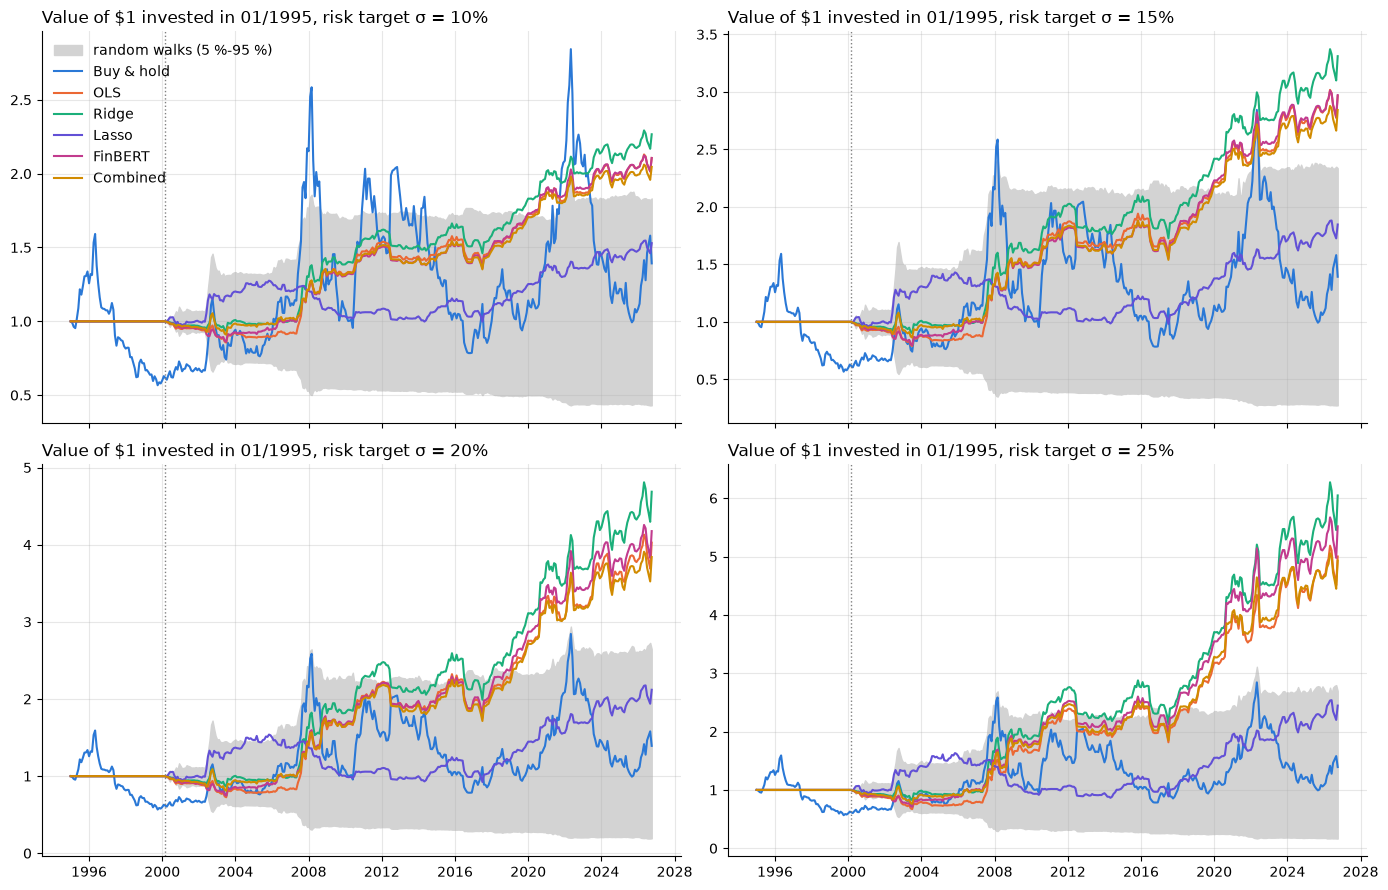

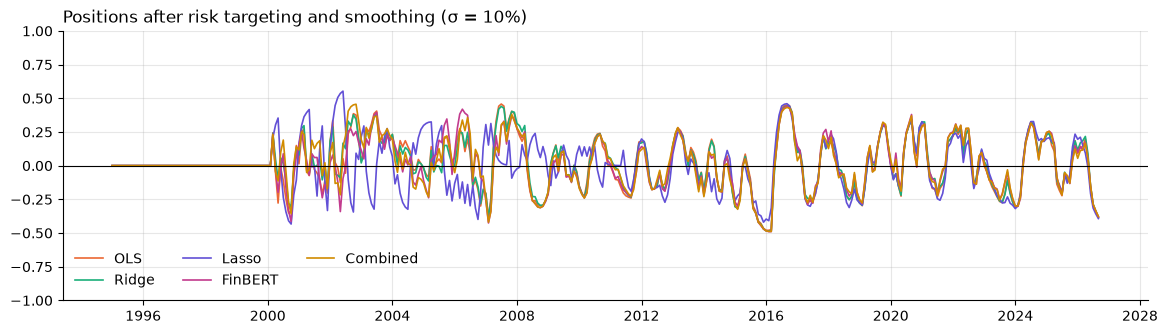

realised volatility                                Sharpe  \
strategy                      OLS  Ridge  Lasso FinBERT Combined    OLS   
risk target σ                                                             
10%                         0.056  0.056  0.049   0.053    0.054  0.526   
15%                         0.084  0.084  0.073   0.080    0.082  0.526   
20%                         0.112  0.111  0.096   0.107    0.108  0.523   
25%                         0.132  0.132  0.113   0.128    0.129  0.523   

                                              
strategy       Ridge  Lasso FinBERT Combined  
risk target σ                                 
10%            0.580  0.351   0.551    0.522  
15%            0.580  0.351   0.551    0.522  
20%            0.579  0.342   0.558    0.522  
25%            0.578  0.353   0.567    0.528

In [157]:
STYLE = {"Buy & hold": "#2a78d6", "OLS": "#eb6834", "Ridge": "#1baf7a", "Lasso": "#6250d6", "FinBERT": "#c23b8e", "Combined": "#d18b00"}
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, sigma in zip(axes.flat, SIGMAS):
    res = results[sigma]
    ax.fill_between(res["random"].index, res["random"].quantile(0.05, axis=1), res["random"].quantile(0.95, axis=1),
                    color="lightgray", label="random walks (5 %-95 %)")
    for name, color in STYLE.items():
        ax.plot(res["values"][name], color=color, label=name)
    ax.axvline(first, color="gray", ls=":", lw=1)
    ax.set_title(f"Value of $1 invested in {model_data.index[0]:%m/%Y}, risk target σ = {sigma:.0%}")
axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
for name in list(ESTIMATORS) + ["FinBERT", "Combined"]:
    ax.plot(results[SIGMAS[0]]["positions"][name], color=STYLE[name], lw=1.2, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-1, 1)
ax.set_title(f"Positions after risk targeting and smoothing (σ = {SIGMAS[0]:.0%})")
ax.legend(loc="lower left", ncol=3)
plt.show()

# Realised volatility vs risk target, and Sharpe ratio, for each model
models = list(ESTIMATORS) + ["FinBERT", "Combined"]
display(pd.concat({"realised volatility": summary["volatility"].unstack()[models],
                   "Sharpe": summary["Sharpe"].unstack()[models]}, axis=1).round(3))

**Reading the results.**
- **Risk use.** The realised volatility stays below the target: the conviction rarely reaches ±1 and the smoothing shrinks the positions further. The risk constraint is respected ex ante but not fully used.
- **Sharpe ratio.** All positions are proportional to σ, so changing the target scales gains and losses but leaves the Sharpe ratio almost unchanged. The choice of σ sets the level of risk taken; it does not create performance.
- **Random walks.** The share of random walks with a higher Sharpe measures how likely the result is to be luck.

**Look-ahead check (placebo test).** All the data from `T0` onwards are replaced by noise and the models are run again. If no future information is used, every position decided up to `T0` must stay identical.

In [158]:
T0 = pd.Timestamp("2015-01-01")
noisy = monthly.copy()
after = noisy.index >= T0
noisy.loc[after] = noisy.loc[after].mask(noisy.loc[after].notna(),
                                         np.random.default_rng(1).uniform(10, 100, noisy.loc[after].shape))
noisy_data = make_model_data(noisy)
for name, make in ESTIMATORS.items():
    check = position(walk_forward(noisy_data, CLIMATE, make), noisy_data, SIGMAS[0])
    reference = results[SIGMAS[0]]["positions"][name]
    print(f"{name}: positions up to {T0:%Y-%m} unchanged: {np.allclose(check[:T0], reference[:T0])}; "
          f"later positions changed: {not np.allclose(check[T0:].iloc[1:], reference[T0:].iloc[1:])}")

OLS: positions up to 2015-01 unchanged: True; later positions changed: True
Ridge: positions up to 2015-01 unchanged: True; later positions changed: True
Lasso: positions up to 2015-01 unchanged: True; later positions changed: True


**Limitations.**
- **Execution**: at the average price of the month, without futures roll costs; cash earns 0 %; short sales are free; trading costs of 10 basis points are an assumption.
- **Model choice**: the El Niño / La Niña coding was suggested by an analysis on the same data. Some selection bias is therefore possible, and the stability of the results over sub-periods should be checked.
- **Sentiment**: the word lists are simple and some words are ambiguous (e.g. *lower* can refer to prices or to production).
- **Data**: current vintages are used, not the values published at the time (the IMF prices and the RONI can be revised).
- **Statistics**: about 23 years of monthly data is a short sample to measure a Sharpe ratio precisely.